# 02 Project finance: cleaning and exploration

Renewable energy project announcements from LSEG's project finance database, January 2024 onwards,
and how they changed after the start of the Iran war (28 February 2026).

**Input:** `data/clean/pf_deals.parquet`, one row per renewable project, built in `01_pf_download_and_panel.ipynb`.

**Output:**
- `output/pf/figures/*.png`: static charts
- `output/pf/pf_dashboard.html`: interactive dashboard 

**Main cleaning choices** :
- Only complete months are kept; the month of the download is dropped.
- Reported costs above USD 50 bn are treated as missing (most look like local currency). The project still counts.
- Records with standardised site-list names (e.g. "solar pv project gela (4)") are flagged. They are dropped in `deals_clean`, which the region line charts use.
- Pre-war months run up to February 2026, post-war months start in March 2026.

**To run:** open from the `notebook/` folder and run all cells.

## Set-up

In [2]:
import json
from html import escape
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly
from IPython.display import HTML, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.interpolate import PchipInterpolator

# notebook sits in notebook/, project root is one level up
root = Path.cwd().parent
clean_dir = root / "data" / "clean"
out_dir = root / "output" / "pf"
fig_dir = out_dir / "figures"
template_file = Path.cwd() / "templates" / "pf_dashboard_template.html"
fig_dir.mkdir(parents=True, exist_ok=True)

# event timing
war_start = pd.Timestamp("2026-02-28")               # start of the Iran war
war_month = war_start.to_period("M").to_timestamp()  # Feb 2026, last pre-war month
post_start = war_month + pd.DateOffset(months=1)     # Mar 2026, first post-war month

# cleaning thresholds
max_cost_usd = 50e9   # reported costs above this are treated as missing
spike_factor = 1.8    # a month is flagged if it has more than 1.8x the median monthly count

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)

### Regions

Countries are grouped into eight regions. Anything not listed falls into "Other";
section 2 lists the largest of those so the mapping can be extended.

In [3]:
regions = {
    "Western Europe": [
        "Austria", "Belgium", "Cyprus", "Denmark", "Finland", "France", "Germany",
        "Greece", "Iceland", "Ireland", "Italy", "Luxembourg", "Malta",
        "Netherlands", "Norway", "Portugal", "Spain", "Sweden", "Switzerland",
        "United Kingdom"],
    "CESEE": [  # EU-CEE and the rest of CESEE together
        "Bulgaria", "Croatia", "Czech Republic", "Estonia", "Hungary", "Latvia",
        "Lithuania", "Poland", "Romania", "Slovakia", "Slovenia",
        "Albania", "Bosnia and Herzegovina", "Kosovo", "Montenegro",
        "North Macedonia", "Serbia", "Moldova", "Ukraine", "Turkey"],
    "North America": ["United States", "Canada"],
    "China": ["China (Mainland)"],
    "Asia & Middle East": [  # rest of Asia plus the Middle East
        "Japan", "South Korea", "Hong Kong", "Taiwan", "Singapore", "India",
        "Indonesia", "Malaysia", "Thailand", "Philippines", "Vietnam",
        "Pakistan", "Bangladesh", "Sri Lanka", "Kazakhstan", "Uzbekistan",
        "United Arab Emirates", "Saudi Arabia", "Qatar", "Kuwait", "Bahrain",
        "Oman", "Israel", "Jordan", "Iraq"],
    "Latin America": [
        "Brazil", "Mexico", "Chile", "Colombia", "Peru", "Argentina", "Uruguay",
        "Panama", "Costa Rica", "Guatemala", "Dominican Republic", "Paraguay",
        "Ecuador"],
    "Africa": [
        "South Africa", "Egypt", "Morocco", "Kenya", "Nigeria", "Ethiopia", "Ghana",
        "Tanzania", "Uganda", "Zambia", "Zimbabwe", "Senegal", "Namibia", "Botswana",
        "Algeria", "Tunisia", "Mozambique", "Ivory Coast", "Cote d'Ivoire", "Cameroon",
        "Angola", "Mali"],   
    "Oceania": ["Australia", "New Zealand"],
}
region_of = {c: r for r, cs in regions.items() for c in cs}
region_order = list(regions) + ["Other"]

# one fixed colour per region, same order in every chart
region_colors = dict(zip(regions, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                   "#e87ba4", "#008300", "#6250d6", "#e34948"]))
region_colors["Other"] = "#8a8984"

## 2. Load and prepare the data

In [4]:
deals = pd.read_parquet(clean_dir / "pf_deals.parquet")
deals["month"] = pd.to_datetime(deals["month"])
deals["region_wiiw"] = deals["country"].map(region_of).fillna("Other")

# keep complete months only (drops the month of the download, if it is in the data)
last_full = min((pd.Timestamp.today().to_period("M") - 1).to_timestamp(), deals["month"].max())
deals = deals[deals["month"] <= last_full].copy()
months = pd.date_range(deals["month"].min(), last_full, freq="MS")
period_label = f"{months[0]:%B %Y} to {months[-1]:%B %Y}"

# implausible costs -> missing (the project stays in the counts)
too_big = deals["cost_usd"] > max_cost_usd
deals["cost_raw"] = deals["cost_usd"]
deals.loc[too_big, "cost_usd"] = np.nan

# site-list records: standard names like "agri pv project gela (4) solar plant project",
# added in batches (see section 3). Flagged here, dropped in deals_clean.
site_list_pattern = r"^(?:agri pv project|onshore wind project|solar pv project|floating pv project)\b.*\(\d+\)"
deals["site_list"] = deals["project_name"].str.lower().str.contains(site_list_pattern, regex=True, na=False)
deals_clean = deals[~deals["site_list"]].copy()

print(f"{len(deals):,} renewable projects, {period_label}")
print(f"{deals['country'].nunique()} countries, {deals['technology'].nunique()} technologies")
print(f"{too_big.sum()} projects with cost above USD {max_cost_usd / 1e9:.0f} bn set to missing")
print(f"{deals['site_list'].sum():,} site-list records flagged, {len(deals_clean):,} projects in deals_clean")

25,251 renewable projects, January 2024 to October 2026
163 countries, 8 technologies
741 projects with cost above USD 50 bn set to missing
5,039 site-list records flagged, 20,212 projects in deals_clean


In [5]:
print("Missing values (%):")
deals.isna().mean().mul(100).round(1).to_frame("missing_pct")

Missing values (%):


,missing_pct
deal_id,0.0
project_name,0.0
announced,0.0
country,0.0
region,0.0
status,0.5
contract_type,0.0
sponsors,59.4
cost_usd,42.9
technology,0.0


In [ ]:
# countries without a region
deals.loc[deals["region_wiiw"] == "Other", "country"].value_counts().head(15)

country
Georgia                  68
Cambodia                 26
Laos                     19
Mauritius                15
Kyrgyzstan               15
Congo (DRC)              13
Azerbaijan               12
Bhutan                   12
Tajikistan               11
Syria                    10
Benin                     9
Sao Tome and Principe     8
Madagascar                8
Chad                      7
Puerto Rico               7
Name: count, dtype: Int64

## 3. Data quality checks


### 3.1 Coverage over time

Months with more than 1.8 times the median count are flagged. The cell below breaks them down to see
whether one country or sponsor drives the spike.

In [7]:
monthly = deals.groupby("month").agg(projects=("deal_id", "count"),
                                     with_cost=("cost_usd", "count"),
                                     cost_bn=("cost_usd", lambda x: x.sum() / 1e9))
monthly["flag"] = np.where(monthly["projects"] > spike_factor * monthly["projects"].median(), "spike?", "")
spike_months = monthly.index[monthly["flag"] != ""]
monthly

,projects,with_cost,cost_bn,flag
month,,,,
2024-01-01,778,486,891.3,
2024-02-01,864,648,766.2,
2024-03-01,845,524,429.8,
2024-04-01,614,386,538.8,
2024-05-01,628,360,431.8,
2024-06-01,863,554,837.1,
2024-07-01,556,346,471.6,
2024-08-01,537,335,319.2,
2024-09-01,771,476,695.9,


In [8]:
for m in spike_months:
    d = deals[deals["month"] == m]
    print(f"\n{m:%b %Y}: {len(d)} projects, {d['site_list'].sum()} site-list records")
    print("  countries:", d["country"].value_counts().head(5).to_dict())
    print("  status:   ", d["status"].value_counts().head(4).to_dict())
    print("  sponsors: ", d["sponsors"].value_counts().head(3).to_dict())


May 2025: 2693 projects, 1150 site-list records
  countries: {'Italy': 2090, 'Vietnam': 172, 'China (Mainland)': 83, 'Germany': 50, 'France': 44}
  status:    {'Announced': 2451, 'Planning Permission Granted': 113, 'Contract Signed': 30, 'Agreement Signed': 21}
  sponsors:  {'Gentari Renewables Sdn Bhd': 4, 'Enlight Renewable Energy Ltd': 3, 'Metlen Energy & Metals Sa': 3}

Jul 2025: 2543 projects, 1796 site-list records
  countries: {'France': 1602, 'Italy': 460, 'Germany': 163, 'China (Mainland)': 65, 'United States': 41}
  status:    {'Announced': 2287, 'Planning Permission Granted': 88, 'Contract Signed': 57, 'Agreement Signed': 25}
  sponsors:  {'CGN Wind Energy Ltd': 7, 'New Leaf Energy Inc': 6, 'Orenda': 5}

Jan 2026: 2494 projects, 1328 site-list records
  countries: {'Italy': 1790, 'Germany': 262, 'United Kingdom': 244, 'South Korea': 46, 'United States': 18}
  status:    {'Announced': 2133, 'Contract Awarded': 169, 'Contract Signed': 110, 'Sale Completed': 18}
  sponsors:  {

### 3.2 Seasonality

Projects per calendar month and year. A recurring pattern (e.g. a December peak) would need to be
accounted for before comparing months around the war.

In [9]:
season = (deals.assign(year=deals["month"].dt.year, cal_month=deals["month"].dt.month)
          .groupby(["cal_month", "year"]).size().unstack())
season.index = pd.to_datetime(season.index, format="%m").strftime("%b")
season

year,2024,2025,2026
cal_month,,,
Jan,778.0,563.0,"2,494.0"
Feb,864.0,814.0,315.0
Mar,845.0,885.0,405.0
Apr,614.0,868.0,550.0
May,628.0,"2,693.0",282.0
Jun,863.0,938.0,200.0
Jul,556.0,"2,543.0",237.0
Aug,537.0,679.0,185.0
Sep,771.0,651.0,134.0


### 3.3 Cost disclosure

Cost is only available for part of the sample, so cost figures are lower bounds. The tables show
disclosure by year, the projects dropped for implausible costs, and how concentrated the remaining cost is.

In [10]:
deals.groupby(deals["month"].dt.year).agg(
    disclosed_pct=("cost_usd", lambda x: x.notna().mean() * 100),
    median_m=("cost_usd", lambda x: x.median() / 1e6),
    total_bn=("cost_usd", lambda x: x.sum() / 1e9))

,disclosed_pct,median_m,total_bn
month,,,
2024,64.9,54.9,"7,433.2"
2025,55.5,46.3,"8,141.0"
2026,47.1,72.5,"3,737.1"


In [11]:
# projects dropped for implausibly large costs: are they in local currency?
print(f"set to missing: {too_big.sum()} projects, {deals.loc[too_big, 'cost_raw'].sum() / 1e12:,.0f} trillion USD as reported")
print(deals.loc[too_big, "country"].value_counts().head(10).to_string())
(deals.loc[too_big, ["project_name", "country", "technology", "month", "cost_raw"]]
      .sort_values("cost_raw", ascending=False).head(15))

set to missing: 741 projects, 5,290 trillion USD as reported
country
Vietnam        288
Colombia        95
Chile           61
India           47
South Korea     41
Uzbekistan      26
Indonesia       25
Cambodia        20
Argentina       18
Philippines     15


,project_name,country,technology,month,cost_raw
18018,Indonesia Java Island Solar Power Project,Indonesia,Solar,2025-08-01,"1,175,380,500,000,430.0"
13752,Nam Bo Offshore Wind Project,Vietnam,Offshore wind,2025-11-01,"1,051,199,999,986,670.0"
24680,Can Gio 2 Offshore Wind Power Plant Project,Vietnam,Offshore wind,2026-05-01,"587,730,000,000,000.0"
1947,CNGR Advanced Material Indonesia Integrated Ba...,Indonesia,Storage,2024-10-01,"164,167,499,999,059.0"
12966,Dak Lak (Vingroup) Solar Project,Vietnam,Solar,2025-04-01,"118,858,500,000,561.0"
4835,Vingroup Can Gio Nearshore Wind Power Project,Vietnam,Onshore wind,2025-05-01,"116,865,000,000,321.0"
12153,Binh Phuoc (Vingroup) Solar Project,Vietnam,Solar,2025-04-01,"105,652,008,660,498.0"
15115,Nam Trung Bo 1 Offshore Wind Project,Vietnam,Offshore wind,2025-08-01,"105,200,000,000,589.0"
4878,Syrian CCGT & Solar Power Plant Project,Syria,Solar,2025-05-01,"91,000,000,000,091.0"
12444,Danantara Indonesia Waste-to-Energy Portfolio ...,Indonesia,Bioenergy,2025-09-01,"91,000,000,000,000.0"


In [12]:
top = deals.nlargest(10, "cost_usd")[["project_name", "country", "technology", "month", "cost_usd"]]
print(f"top 10 projects = {top['cost_usd'].sum() / deals['cost_usd'].sum() * 100:.0f}% of all disclosed cost")
top.assign(cost_usd_bn=top["cost_usd"] / 1e9).drop(columns="cost_usd")

top 10 projects = 3% of all disclosed cost


,project_name,country,technology,month,cost_usd_bn
8078,Avaada Group Bihar Solar & Battery storage Pla...,India,Solar + storage,2025-07-01,50.0
25055,RSOLEC Tumakuru Solar Ingot & Wafer Manufactur...,India,Solar,2025-05-01,50.0
16864,Gyeongju Dasan Wind Power Plant Project,South Korea,Onshore wind,2025-02-01,49.8
770,Ayg-1 Solar Project,Armenia,Solar,2024-02-01,49.0
12433,KPI Green Energy Gujarat Solar & Wind Project,India,Solar,2025-04-01,48.5
2386,KX Renewable Energy Small Scale Solar Power Po...,Japan,Solar,2024-11-01,48.2
14113,Gutami Solar PV Project,Burkina Faso,Solar,2025-01-01,47.9
8885,Ayg-2 SPP Solar Plant Project,Armenia,Solar,2025-03-01,47.7
21885,Dangjin Daehoji Solar Park #1 Project,South Korea,Solar,2024-07-01,47.6
24919,Plenitude Badamsha 3 Wind Farm Project,Kazakhstan,Onshore wind,2026-05-01,47.1


## 4. Descriptive statistics

### 4.1 Regions and countries



In [13]:
by_region = (deals.groupby("region_wiiw")
             .agg(projects=("deal_id", "count"), countries=("country", "nunique"),
                  cost_bn=("cost_usd", lambda x: x.sum() / 1e9),
                  cost_disclosed_pct=("cost_usd", lambda x: x.notna().mean() * 100))
             .reindex(region_order).dropna(how="all"))
by_region["share_pct"] = by_region["projects"] / by_region["projects"].sum() * 100
by_region.sort_values("projects", ascending=False)

,projects,countries,cost_bn,cost_disclosed_pct,share_pct
region_wiiw,,,,,
Western Europe,14294,18,704.4,61.8,56.6
Asia & Middle East,2806,24,"8,106.3",32.4,11.1
China,2491,1,"2,782.1",69.0,9.9
North America,1813,2,193.8,39.8,7.2
Latin America,1159,13,"2,783.6",68.7,4.6
Oceania,823,2,294.4,50.7,3.3
CESEE,805,19,918.7,44.7,3.2
Africa,674,21,"2,357.6",66.5,2.7
Other,386,63,"1,170.3",55.4,1.5


In [14]:
by_country = deals["country"].value_counts()
print(f"top 10 countries = {by_country.head(10).sum() / by_country.sum() * 100:.0f}% of all projects")
by_country.head(20).to_frame("projects").assign(region=lambda d: d.index.map(region_of).fillna("Other"))

top 10 countries = 80% of all projects


,projects,region
country,,
Italy,5522,Western Europe
France,3151,Western Europe
Germany,2889,Western Europe
China (Mainland),2491,China
United States,1742,North America
United Kingdom,1683,Western Europe
India,922,Asia & Middle East
Australia,681,Oceania
Brazil,633,Latin America


### 4.2 Technologies

In [15]:
tech = deals.groupby("technology").agg(projects=("deal_id", "count"),
                                       cost_bn=("cost_usd", lambda x: x.sum() / 1e9),
                                       median_cost_m=("cost_usd", lambda x: x.median() / 1e6))
tech["share_pct"] = tech["projects"] / tech["projects"].sum() * 100
tech.sort_values("projects", ascending=False)

,projects,cost_bn,median_cost_m,share_pct
technology,,,,
Solar,11247,"10,370.1",26.8,44.5
Onshore wind,8464,"5,955.8",60.6,33.5
Storage,4215,"1,099.6",261.8,16.7
Solar + storage,791,962.0,400.0,3.1
Hydro,178,484.5,"1,471.1",0.7
Bioenergy,168,148.7,151.2,0.7
Offshore wind,145,235.9,"3,191.6",0.6
Geothermal,43,54.8,"1,471.2",0.2


### 4.3 Project status before and after the war



In [16]:
(pd.crosstab(deals["status"], deals["month"] >= post_start, normalize="columns")
   .mul(100).round(1)
   .rename(columns={False: "before war %", True: "after war %"})
   .sort_values("before war %", ascending=False))

month,before war %,after war %
status,,
Announced,53.1,51.6
Planning Permission Granted,21.7,0.3
Under Construction,5.8,3.1
Contract Signed,4.2,6.9
Operational,2.6,0.4
Agreement Signed,2.3,4.7
Contract Awarded,2.2,6.3
Sale Completed,2.0,6.5
Completed,1.3,1.0


## 5. Static figures



In [17]:
blue, blue_light, ink, ink_soft, grid_c, shade = "#2a78d6", "#9cc0ec", "#0b0b0b", "#52514e", "#ebeae5", "#f3f2ee"
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bdbcb6",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": grid_c, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": ink_soft, "ytick.color": ink_soft, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.titleweight": "semibold", "legend.frameon": False,
})
source_note = "Source: LSEG Workspace, project finance database; author's calculations."
cost_note = f" Only projects with a disclosed cost; values above USD {max_cost_usd / 1e9:.0f} bn treated as missing."
period_end = last_full + pd.offsets.MonthEnd(0)


def smooth_line(dates, values, points=400):
    """Monotone (PCHIP) interpolation for drawing, so the smoothed line never overshoots the data."""
    ok = ~np.isnan(values)
    t = mdates.date2num(dates[ok])
    tt = np.linspace(t.min(), t.max(), points)
    return mdates.num2date(tt), np.clip(PchipInterpolator(t, values[ok])(tt), 0, None)


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(length=0, labelsize=8.5)

### 5.1 Monthly projects and cost by region



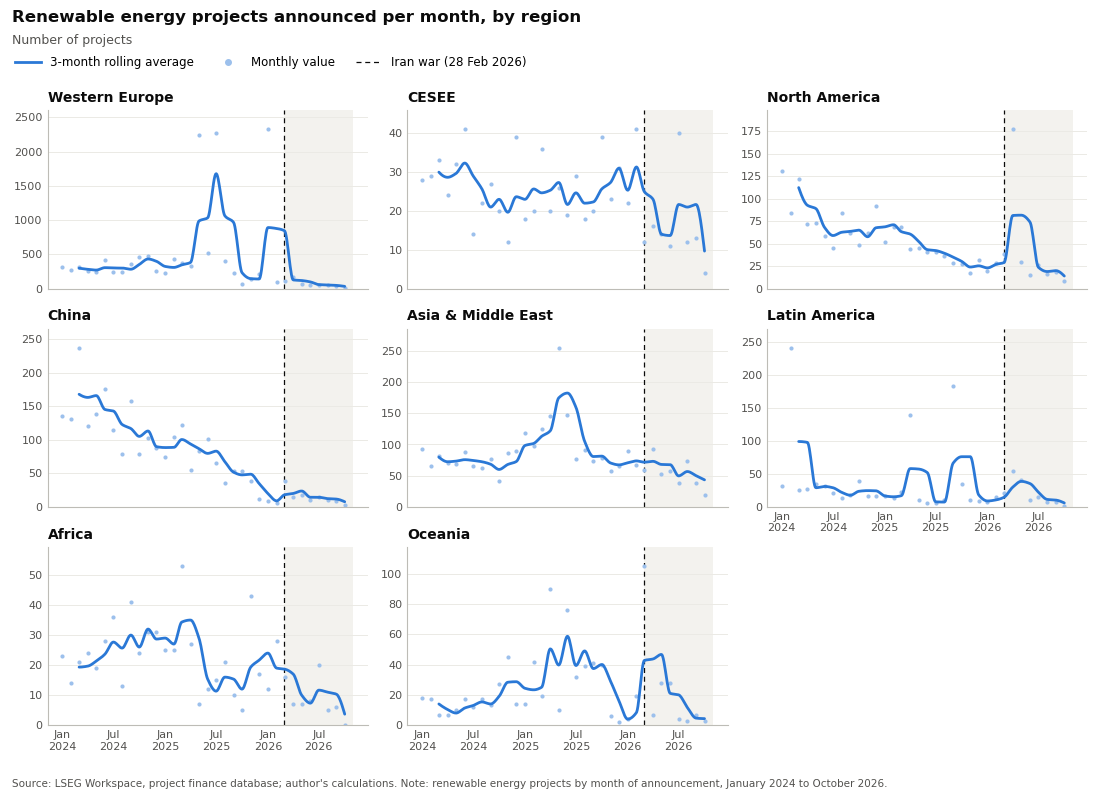

In [18]:
def region_panels(measure, title, ylabel, name):
    if measure == "n":
        tab = deals.groupby(["region_wiiw", "month"]).size()
    else:
        tab = deals.groupby(["region_wiiw", "month"])["cost_usd"].sum() / 1e9
    tab = tab.unstack(0).reindex(months).fillna(0)
    show = [r for r in region_order if r != "Other" and r in tab.columns]

    ncol = 3
    nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(11, 2.35 * nrow + 0.9), sharex=True)
    for ax, r in zip(axes.flat, show):
        monthly_v = tab[r].values
        avg3 = tab[r].rolling(3).mean().values
        ax.axvspan(war_start, period_end, color=shade, zorder=0, lw=0)
        ax.axvline(war_start, color=ink, lw=0.9, ls=(0, (4, 3)))
        ax.scatter(tab.index, monthly_v, s=9, color=blue_light, zorder=2, lw=0)
        xs, ys = smooth_line(tab.index, avg3)
        ax.plot(xs, ys, color=blue, lw=2, zorder=3, solid_capstyle="round")
        ax.set_title(r, color=ink)
        ax.set_ylim(0, max(monthly_v.max(), 1e-9) * 1.12)
        date_axis(ax)
        ax.tick_params(labelsize=8)
    for ax in list(axes.flat)[len(show):]:
        ax.set_visible(False)
    # x labels on the lowest visible panel of each column
    for i in range(max(len(show) - ncol, 0), len(show)):
        axes.flat[i].xaxis.set_tick_params(labelbottom=True)

    handles = [Line2D([], [], color=blue, lw=2, label="3-month rolling average"),
               Line2D([], [], color=blue_light, marker="o", lw=0, markersize=4, label="Monthly value"),
               Line2D([], [], color=ink, lw=0.9, ls=(0, (4, 3)), label="Iran war (28 Feb 2026)")]
    fig.tight_layout(rect=(0, 0.035, 1, 0.9))
    fig.text(0.01, 0.985, title, fontsize=12, fontweight="semibold", color=ink, ha="left", va="top")
    fig.text(0.01, 0.955, ylabel, fontsize=9, color=ink_soft, ha="left", va="top")
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.003, 0.94), ncol=3, fontsize=8.5,
               handlelength=2.2, columnspacing=1.8)
    note = f"{source_note} Note: renewable energy projects by month of announcement, {period_label}."
    if measure != "n":
        note += cost_note
    fig.text(0.01, 0.005, note, fontsize=7.5, color=ink_soft, ha="left", va="bottom", wrap=True)
    fig.savefig(fig_dir / f"{name}.png", dpi=220, bbox_inches="tight")
    plt.show()


region_panels("n", "Renewable energy projects announced per month, by region",
              "Number of projects", "pf_projects_by_region")

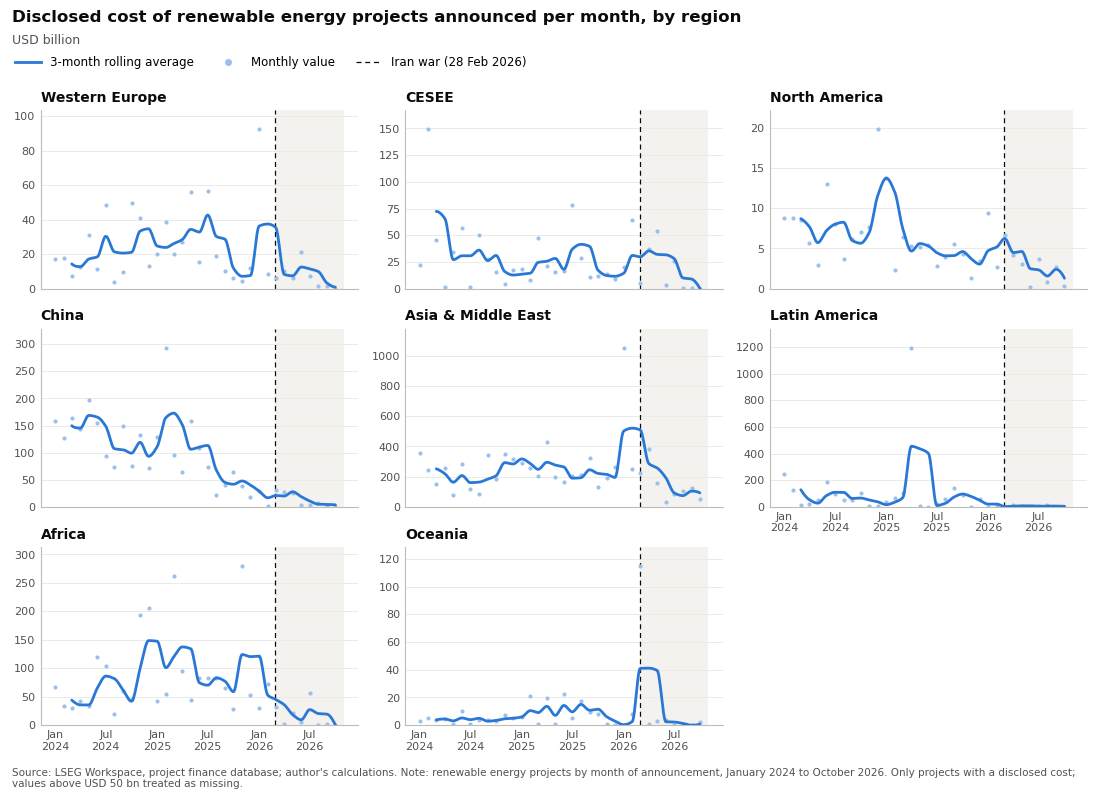

In [19]:
region_panels("cost", "Disclosed cost of renewable energy projects announced per month, by region",
              "USD billion", "pf_cost_by_region")

### 5.2 All regions on one chart



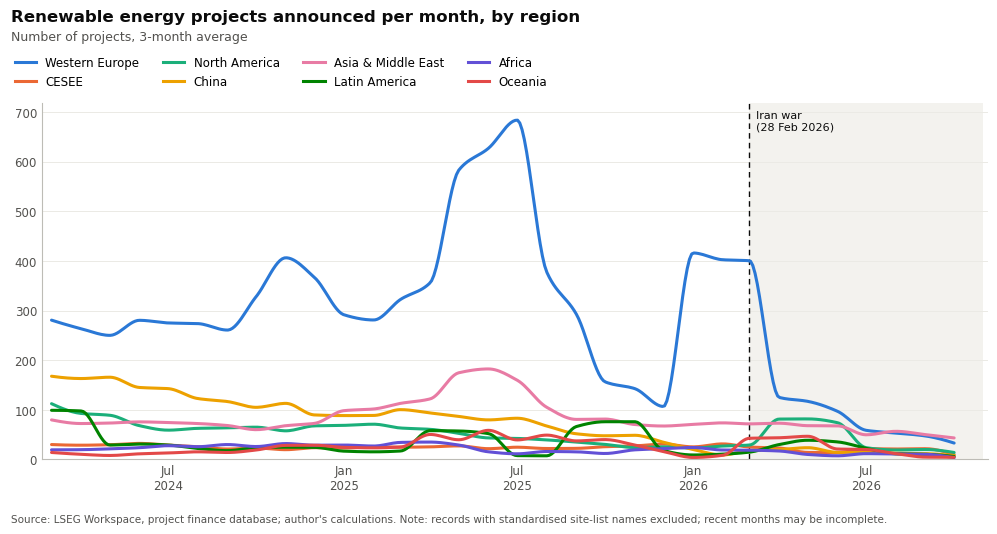

In [20]:
def region_lines(mode="level", smooth=3, data=None, name=None):
    d = deals_clean if data is None else data
    tab = (d.groupby(["region_wiiw", "month"]).size().unstack(0)
           .reindex(index=months).fillna(0))
    show = [r for r in regions if r in tab.columns]          # "Other" left out
    avg = tab[show].rolling(smooth).mean() if smooth > 1 else tab[show]
    avg = avg.dropna(how="all")

    if mode == "index":
        pre = pd.date_range(war_month - pd.DateOffset(months=11), war_month, freq="MS")
        base = tab.loc[tab.index.isin(pre), show].mean()
        avg = avg / base * 100

    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.axvspan(war_start, period_end, color=shade, zorder=0, lw=0)
    ax.axvline(war_start, color=ink, lw=1, ls=(0, (4, 3)), zorder=1)
    if mode == "index":
        ax.axhline(100, color=ink_soft, lw=0.8, zorder=1)

    for r in show:
        xs, ys = smooth_line(avg.index, avg[r].values)
        ax.plot(xs, ys, color=region_colors[r], lw=2.2, solid_capstyle="round", zorder=3, label=r)
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top)

    ax.text(war_start + pd.Timedelta(days=8), top * 0.98, "Iran war\n(28 Feb 2026)",
            ha="left", va="top", fontsize=8, color=ink)
    ax.set_xlim(avg.index[0] - pd.Timedelta(days=10), period_end + pd.Timedelta(days=5))
    date_axis(ax)

    fig.legend(handles=[Line2D([], [], color=region_colors[r], lw=2.2, label=r) for r in show],
               loc="upper left", bbox_to_anchor=(0.003, 0.925), ncol=4, fontsize=8.5, handlelength=1.8)
    title = "Renewable energy projects announced per month, by region"
    avg_txt = f", {smooth}-month average" if smooth > 1 else ""
    sub = ("Number of projects" if mode == "level"
           else "Index, average of the 12 months before the war = 100") + avg_txt
    fig.text(0.01, 0.995, title, fontsize=12, fontweight="semibold", color=ink, ha="left", va="top")
    fig.text(0.01, 0.955, sub, fontsize=9, color=ink_soft, ha="left", va="top")
    fig.tight_layout(rect=(0, 0.04, 1, 0.84))
    fig.text(0.01, 0.005, f"{source_note} Note: records with standardised site-list names excluded; "
             "recent months may be incomplete.", fontsize=7.5, color=ink_soft, ha="left", va="bottom")
    name = name or f"pf_region_lines_{mode}"
    fig.savefig(fig_dir / f"{name}.png", dpi=220, bbox_inches="tight")
    plt.show()


region_lines(mode="level")

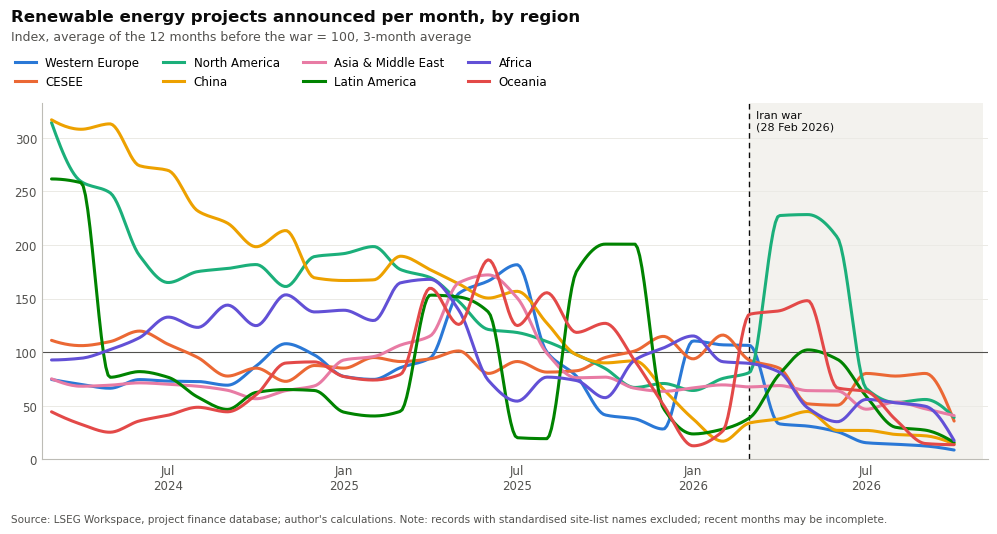

In [21]:
region_lines(mode="index")

### 5.3 Heatmap: timing by region


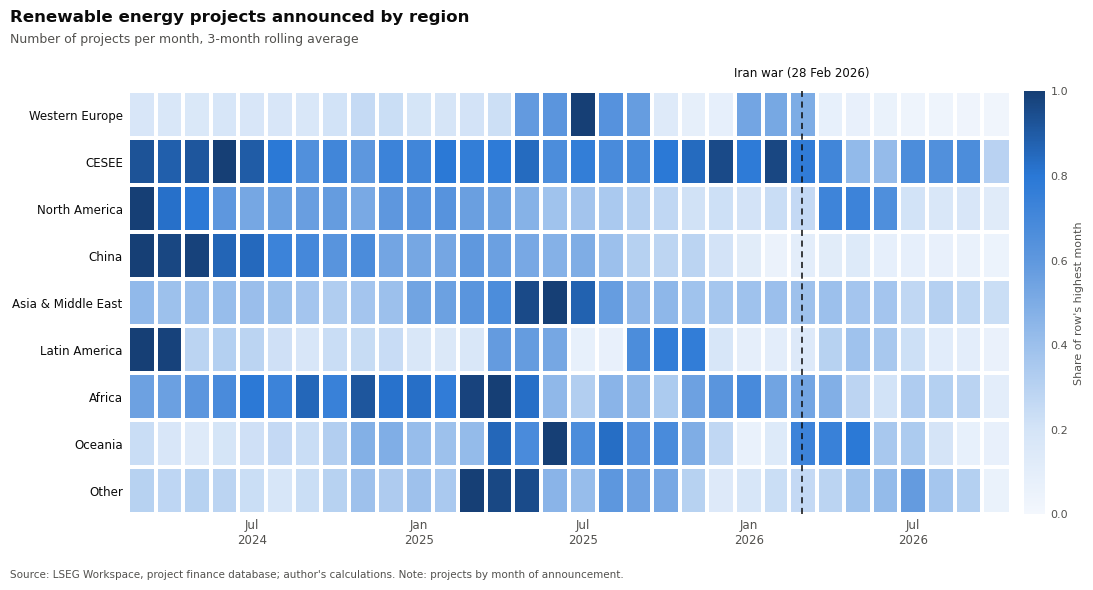

In [22]:
def region_heatmap(measure="n", relative=True, smooth=3, technology=None, name=None):
    d = deals if technology is None else deals[deals["technology"] == technology]
    if measure == "n":
        tab = d.groupby(["region_wiiw", "month"]).size()
    else:
        tab = d.groupby(["region_wiiw", "month"])["cost_usd"].sum() / 1e9
    tab = tab.unstack("month").reindex(columns=months).fillna(0)
    tab = tab.reindex([r for r in region_order if r in tab.index])
    if smooth > 1:
        tab = tab.T.rolling(smooth).mean().T.iloc[:, smooth - 1:]
    shown = tab.div(tab.max(axis=1).replace(0, np.nan), axis=0) if relative else tab

    cmap = LinearSegmentedColormap.from_list(
        "blues", ["#f3f7fd", "#d4e4f7", "#9cc0ec", "#5f98de", "#2a78d6", "#163f75"])

    fig, ax = plt.subplots(figsize=(11, 0.42 * len(tab) + 1.8))
    x = mdates.date2num(tab.columns)
    step = x[1] - x[0]
    mesh = ax.pcolormesh(np.append(x - step / 2, x[-1] + step / 2), np.arange(len(tab) + 1), shown.values,
                         cmap=cmap, vmin=0, edgecolors="white", linewidth=1.5)
    ax.set_yticks(np.arange(len(tab)) + 0.5, tab.index, color=ink)
    ax.invert_yaxis()
    ax.xaxis_date()
    date_axis(ax)
    ax.grid(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)

    ax.axvline(war_start, color=ink, lw=1.1, ls=(0, (4, 3)))
    ax.text(war_start, -0.25, "Iran war (28 Feb 2026)", ha="center", va="bottom", fontsize=8.5, color=ink)

    cb = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.015)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8, length=0, colors=ink_soft)
    unit = "Number of projects" if measure == "n" else "USD billion"
    cb.set_label("Share of row's highest month" if relative else unit, fontsize=8, color=ink_soft)

    what = technology or "Renewable energy"
    title = (f"{what} projects announced by region" if measure == "n"
             else f"Disclosed cost of {what.lower()} projects announced by region")
    sub = f"{unit} per month" + (f", {smooth}-month rolling average" if smooth > 1 else "")
    fig.text(0.01, 1.0, title, fontsize=12, fontweight="semibold", color=ink, ha="left", va="bottom")
    fig.text(0.01, 0.985, sub, fontsize=9, color=ink_soft, ha="left", va="top")
    fig.tight_layout(rect=(0, 0.04, 1, 0.95))
    note = f"{source_note} Note: projects by month of announcement."
    if measure != "n":
        note += cost_note
    fig.text(0.01, 0.005, note, fontsize=7.5, color=ink_soft, ha="left", va="bottom")

    name = name or f"pf_heatmap_{'projects' if measure == 'n' else 'cost'}{'_relative' if relative else ''}"
    fig.savefig(fig_dir / f"{name}.png", dpi=220, bbox_inches="tight")
    plt.show()


region_heatmap(measure="n", relative=True)
# other versions:
# region_heatmap(measure="n", relative=False)      # absolute numbers
# region_heatmap(measure="cost", relative=True)    # disclosed cost
# region_heatmap(technology="Solar")               # one technology

## 6. Interactive dashboard

The data goes into the page as a compact table (month × country × technology) and the browser does the filtering.

- **Filters:** region, then country (the list follows the region), technology, projects or disclosed cost, monthly or 3-month average
- **Top 5 countries** before the war (12 months to Feb 2026) and since (Mar 2026 on), average per month, same scale
- **Level over time:** smoothed line, monthly dots, unusually high months circled, dashed line at the start of the war
- **Technology mix:** stacked areas for the selected place
- **Heatmap:** regions × months, or the countries of the selected region; "relative to own peak" compares timing

In [23]:
countries = sorted(deals["country"].dropna().unique())
techs = deals["technology"].value_counts().index.tolist()   # largest first, fixed colour order
regions_present = [r for r in region_order if r in set(deals["region_wiiw"])]

agg = (deals.groupby(["month", "country", "technology"])
       .agg(n=("deal_id", "count"), cost=("cost_usd", "sum"), n_cost=("cost_usd", "count"))
       .reset_index())
m_idx = {m: i for i, m in enumerate(months)}
c_idx = {c: i for i, c in enumerate(countries)}
t_idx = {t: i for i, t in enumerate(techs)}
rows = [[m_idx[r.month], c_idx[r.country], t_idx[r.technology], int(r.n), round(float(r.cost)), int(r.n_cost)]
        for r in agg.itertuples(index=False)]

dash_data = {
    "months": [m.strftime("%b %Y") for m in months],
    "months_dt": [m.strftime("%Y-%m-%d") for m in months],
    "war_month": war_month.strftime("%b %Y"),
    "war_date": war_start.strftime("%Y-%m-%d"),
    "end_date": period_end.strftime("%Y-%m-%d"),
    "countries": countries,
    "region_of": {c: region_of.get(c, "Other") for c in countries},
    "regions": regions_present,
    "techs": techs,
    "rows": rows,
    "spike_months": [m.strftime("%Y-%m-%d") for m in spike_months],
}
print(f"{len(rows):,} cells, {len(json.dumps(dash_data)) / 1e3:.0f} kB of data")

3,549 cells, 103 kB of data


In [24]:
# page layout for the dashboard: placeholders like __DATA__ are filled in by build_html below
dash_template = r"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>Renewable energy project announcements and the 2026 Iran war</title>
__PLOTLY__
<style>
  :root {
    --surface: #fcfcfb; --card: #ffffff; --border: #e6e5e0;
    --ink: #0b0b0b; --ink-2: #52514e; --ink-3: #8a8984; --accent: #2a78d6;
  }
  * { box-sizing: border-box; }
  body { margin: 0; background: var(--surface); color: var(--ink);
         font: 14px/1.45 -apple-system, BlinkMacSystemFont, "Segoe UI", Inter, Roboto, sans-serif; }
  .wrap { max-width: 1180px; margin: 0 auto; padding: 28px 24px 32px; }
  h1 { font-size: 22px; font-weight: 600; margin: 0 0 4px; letter-spacing: -0.01em; }
  .sub { color: var(--ink-2); margin: 0 0 20px; }
  .filters { display: flex; flex-wrap: wrap; gap: 14px; align-items: flex-end;
             background: var(--card); border: 1px solid var(--border); border-radius: 12px;
             padding: 14px 16px; margin-bottom: 16px; position: sticky; top: 8px; z-index: 5; }
  .f { display: flex; flex-direction: column; gap: 4px; }
  .f label, .lab { font-size: 11px; text-transform: uppercase; letter-spacing: .06em; color: var(--ink-3); }
  select { font: inherit; padding: 6px 28px 6px 10px; border: 1px solid var(--border); border-radius: 8px;
           background: #fff; color: var(--ink); min-width: 150px; }
  .seg { display: inline-flex; border: 1px solid var(--border); border-radius: 8px; overflow: hidden; }
  .seg button { font: inherit; border: 0; background: #fff; padding: 6px 12px; cursor: pointer; color: var(--ink-2); }
  .seg button + button { border-left: 1px solid var(--border); }
  .seg button.on { background: var(--accent); color: #fff; }
  .card { background: var(--card); border: 1px solid var(--border); border-radius: 12px; padding: 16px 16px 8px; margin-bottom: 16px; }
  .card h2 { font-size: 15px; font-weight: 600; margin: 0; }
  .card .h { display: flex; justify-content: space-between; align-items: center; gap: 12px; flex-wrap: wrap; }
  .card p.note { color: var(--ink-2); font-size: 12px; margin: 2px 0 0; }
  .rank { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; margin-top: 10px; }
  .rank .lab { margin-bottom: 2px; }
  .src { color: var(--ink-3); font-size: 11px; margin-top: 8px; }
  @media (max-width: 900px) { .rank { grid-template-columns: 1fr; } }
</style>
</head>
<body>
<div class="wrap">
  <h1>Renewable energy project announcements and the 2026 Iran war</h1>
  <p class="sub">Renewable energy projects in LSEG's project finance database, by month of announcement, __FIRST__ to __LAST__.</p>

  <div class="filters">
    <div class="f"><label for="region">Region</label><select id="region"></select></div>
    <div class="f"><label for="country">Country</label><select id="country"></select></div>
    <div class="f"><label for="tech">Technology</label><select id="tech"></select></div>
    <div class="f"><label>Measure</label>
      <div class="seg" id="measure"><button data-v="n" class="on">Number of projects</button><button data-v="cost">Disclosed cost</button></div></div>
    <div class="f"><label>Series</label>
      <div class="seg" id="smooth"><button data-v="1">Monthly</button><button data-v="3" class="on">3-month average</button></div></div>
  </div>

  <div class="card">
    <div class="h"><h2 id="t0"></h2></div>
    <p class="note" id="n0"></p>
    <div class="rank">
      <div><div class="lab" id="r1l"></div><div id="r1" style="height:210px"></div></div>
      <div><div class="lab" id="r2l"></div><div id="r2" style="height:210px"></div></div>
    </div>
  </div>

  <div class="card">
    <div class="h"><h2 id="t1"></h2></div>
    <p class="note" id="n1"></p>
    <div id="c1" style="height:400px"></div>
  </div>

  <div class="card">
    <div class="h"><h2 id="t2"></h2></div>
    <p class="note" id="n2"></p>
    <div id="c2" style="height:400px"></div>
  </div>

  <div class="card">
    <div class="h"><h2 id="t3"></h2>
      <div class="seg" id="hscale"><button data-v="abs" class="on">Absolute</button><button data-v="row">Relative to own peak</button></div></div>
    <p class="note" id="n3"></p>
    <div id="c3"></div>
  </div>

  <p class="src">Source: LSEG Workspace, project finance database; author's calculations.
  Notes: Projects are counted in the month they were announced; announcements are not committed investment.
  Technology is assigned from project names. Costs cover only projects with a disclosed total project cost.
  Recent months may be revised upwards as LSEG adds projects. Built __BUILT__.</p>
</div>

<script>
const D = __DATA__;
const TECH_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"];
const SEQ = [[0, "#f3f7fd"], [0.15, "#d4e4f7"], [0.35, "#9cc0ec"], [0.6, "#5f98de"], [0.8, "#2a78d6"], [1, "#163f75"]];
const BLUE = "#2a78d6", BLUE_LIGHT = "#9cc0ec", INK = "#0b0b0b", INK2 = "#52514e", GRID = "#efeee9";
const WAR_LABEL = "Iran war (28 Feb 2026)";

const st = { region: "All", country: "All", tech: "All", measure: "n", smooth: 3, hscale: "abs" };
const M = D.months.length;
const warIdx = D.months.indexOf(D.war_month);
const preFrom = Math.max(0, warIdx - 11), preTo = warIdx;      // 12 months up to and incl. Feb 2026
const postFrom = warIdx + 1, postTo = M - 1;                   // Mar 2026 onwards
const spikeSet = new Set(D.spike_months);

// ---------- filters ----------
const $ = id => document.getElementById(id);
function fill(sel, opts) {
  sel.innerHTML = "";
  ["All", ...opts].forEach(o => { const e = document.createElement("option"); e.value = o; e.textContent = o; sel.appendChild(e); });
}
fill($("region"), D.regions);
fill($("tech"), D.techs);
function countryOptions() {
  const cs = D.countries.filter(c => st.region === "All" || D.region_of[c] === st.region);
  fill($("country"), cs);
  $("country").value = cs.includes(st.country) ? st.country : "All";
  st.country = $("country").value;
}
countryOptions();
$("region").onchange = e => { st.region = e.target.value; countryOptions(); draw(); };
$("country").onchange = e => { st.country = e.target.value; draw(); };
$("tech").onchange = e => { st.tech = e.target.value; draw(); };
function seg(id, key, num) {
  $(id).querySelectorAll("button").forEach(b => b.onclick = () => {
    $(id).querySelectorAll("button").forEach(x => x.classList.remove("on")); b.classList.add("on");
    st[key] = num ? +b.dataset.v : b.dataset.v; draw();
  });
}
seg("measure", "measure"); seg("smooth", "smooth", true); seg("hscale", "hscale");

// ---------- data helpers ----------
// rows: [month_idx, country_idx, tech_idx, n, cost_usd, n_with_cost]
const regionOK = ci => st.region === "All" || D.region_of[D.countries[ci]] === st.region;
const geoOK = ci => st.country !== "All" ? D.countries[ci] === st.country : regionOK(ci);
const techOK = ti => st.tech === "All" || D.techs[ti] === st.tech;
const val = r => st.measure === "n" ? r[3] : r[4] / 1e9;
function series(pred) {
  const s = new Array(M).fill(0);
  for (const r of D.rows) if (pred(r)) s[r[0]] += val(r);
  return s;
}
function roll(s, k) {
  if (k === 1) return s.slice();
  return s.map((_, i) => i < k - 1 ? null : s.slice(i - k + 1, i + 1).reduce((a, b) => a + b, 0) / k);
}
const geoName = () => st.country !== "All" ? st.country : st.region === "All" ? "world" : st.region;
const techWord = () => st.tech === "All" ? "Renewable energy" : st.tech;
const unitLong = () => st.measure === "n" ? "Number of projects" : "USD billion";
const fmtV = v => st.measure === "n" ? v.toFixed(1) : v.toFixed(2);
const period = (a, b) => `${D.months[a]}–${D.months[b]}`;

function warShapes(withShade) {
  const s = [{ type: "line", xref: "x", yref: "paper", x0: D.war_date, x1: D.war_date, y0: 0, y1: 1,
               line: { color: INK, width: 1.2, dash: "dash" } }];
  if (withShade) s.unshift({ type: "rect", xref: "x", yref: "paper", x0: D.war_date, x1: D.end_date, y0: 0, y1: 1,
                             fillcolor: "#f3f2ee", line: { width: 0 }, layer: "below" });
  return s;
}
const warNote = { x: D.war_date, y: 1, xref: "x", yref: "paper", text: WAR_LABEL, showarrow: false,
                  xanchor: "left", yanchor: "top", xshift: 5, font: { size: 11, color: INK } };
function baseLayout(extra) {
  return Object.assign({
    margin: { l: 56, r: 16, t: 28, b: 40 }, paper_bgcolor: "rgba(0,0,0,0)", plot_bgcolor: "rgba(0,0,0,0)",
    font: { family: "-apple-system, BlinkMacSystemFont, Segoe UI, Inter, Roboto, sans-serif", size: 12, color: INK2 },
    xaxis: { type: "date", showgrid: false, linecolor: "#cfcec8", tickformat: "%b\n%Y", dtick: "M6", ticks: "outside",
             tickcolor: "#cfcec8", hoverformat: "%B %Y" },
    yaxis: { gridcolor: GRID, zeroline: false, rangemode: "tozero", title: { text: unitLong(), font: { size: 11 } } },
    hovermode: "x unified", hoverlabel: { bgcolor: "#fff", bordercolor: "#e6e5e0", font: { color: INK } },
    shapes: warShapes(true), annotations: [warNote], showlegend: false,
  }, extra || {});
}
const legendTop = { orientation: "h", x: 0, y: 1.1, xanchor: "left", yanchor: "bottom", font: { size: 12, color: INK2 }, traceorder: "normal" };
const cfg = { displaylogo: false, responsive: true, modeBarButtonsToRemove: ["select2d", "lasso2d", "autoScale2d", "toggleSpikelines"] };

// ---------- ranking ----------
function topCountries(a, b) {
  const tot = {};
  for (const r of D.rows) if (r[0] >= a && r[0] <= b && regionOK(r[1]) && techOK(r[2])) tot[r[1]] = (tot[r[1]] || 0) + val(r);
  const n = b - a + 1;
  return Object.entries(tot).map(([ci, v]) => [D.countries[ci], v / n]).sort((x, y) => y[1] - x[1]).slice(0, 5);
}
function rankChart(div, data, color, xmax) {
  const names = data.map(d => d[0]).reverse(), vals = data.map(d => d[1]).reverse();
  const cols = names.map(c => st.country !== "All" && c === st.country ? "#163f75" : color);
  Plotly.react(div, [{ type: "bar", orientation: "h", x: vals, y: names, marker: { color: cols },
                       text: vals.map(fmtV), textposition: "outside", cliponaxis: false,
                       textfont: { size: 12, color: INK2 },
                       hovertemplate: `%{y}: %{x:.2f} ${st.measure === "n" ? "projects" : "USD bn"} per month<extra></extra>` }],
    { margin: { l: 130, r: 40, t: 4, b: 24 }, paper_bgcolor: "rgba(0,0,0,0)", plot_bgcolor: "rgba(0,0,0,0)",
      font: { family: "-apple-system, BlinkMacSystemFont, Segoe UI, Inter, Roboto, sans-serif", size: 12, color: INK2 },
      xaxis: { range: [0, xmax * 1.15], gridcolor: GRID, zeroline: false, tickfont: { size: 10 } },
      yaxis: { automargin: true, tickfont: { size: 12, color: INK }, range: [names.length - 5.5, names.length - 0.5] },
      bargap: 0.35, showlegend: false },
    { displayModeBar: false, responsive: true });
}

function draw() {
  const k0 = st.smooth - 1;
  const x = D.months_dt.slice(k0);
  const cut = a => a.slice(k0);
  const sel = r => geoOK(r[1]) && techOK(r[2]);
  const perMonth = st.measure === "n" ? "projects per month" : "USD billion per month";

  // 0. top 5 countries before and since the war
  const where = st.region === "All" ? "worldwide" : `in ${st.region}`;
  $("t0").textContent = `Top 5 countries ${where}: ${techWord().toLowerCase()} ${st.measure === "n" ? "projects" : "project cost"} before and since the Iran war`;
  $("n0").textContent = `Average ${perMonth}. ` + (st.country !== "All" ? ` ${st.country} highlighted if in the top 5.` : "");
  const pre = topCountries(preFrom, preTo), post = topCountries(postFrom, postTo);
  const xmax = Math.max(1e-9, ...pre.map(d => d[1]), ...post.map(d => d[1]));
  $("r1l").textContent = `Before the war · ${period(preFrom, preTo)}`;
  $("r2l").textContent = `Since the war · ${period(postFrom, postTo)}`;
  rankChart("r1", pre, BLUE_LIGHT, xmax);
  rankChart("r2", post, BLUE, xmax);

  // 1. level over time
  const raw = series(sel), sm = roll(raw, st.smooth);
  $("t1").textContent = st.measure === "n"
    ? `${techWord()} projects announced per month, ${geoName()}`
    : `Disclosed cost of ${techWord().toLowerCase()} projects announced per month, ${geoName()}`;
  $("n1").textContent = st.measure === "n" ? "Number of projects" : "USD billion";
  const tr1 = [];
  if (st.smooth === 3) {
    tr1.push({ x, y: cut(sm), type: "scatter", mode: "lines", name: "3-month average",
               line: { shape: "spline", smoothing: 0.9, width: 3, color: BLUE },
               fill: "tozeroy", fillcolor: "rgba(42,120,214,0.07)", hovertemplate: "3-month average: %{y:.1f}<extra></extra>" });
    tr1.push({ x, y: cut(raw), type: "scatter", mode: "markers", name: "Monthly value",
               marker: { size: 6, color: BLUE_LIGHT }, hovertemplate: "Monthly value: %{y:.1f}<extra></extra>" });
  } else {
    tr1.push({ x, y: cut(raw), type: "scatter", mode: "lines+markers", name: "Monthly value",
               line: { shape: "spline", smoothing: 0.9, width: 2.5, color: BLUE }, marker: { size: 6, color: BLUE },
               fill: "tozeroy", fillcolor: "rgba(42,120,214,0.07)", hovertemplate: "Monthly value: %{y:.1f}<extra></extra>" });
  }
  const sx = [], sy = [];
  D.months_dt.forEach((m, i) => { if (spikeSet.has(m) && i >= k0) { sx.push(m); sy.push(raw[i]); } });
  if (sx.length && st.measure === "n") tr1.push({ x: sx, y: sy, type: "scatter", mode: "markers", name: "Unusually high month",
                            marker: { size: 13, color: "rgba(0,0,0,0)", line: { color: INK2, width: 1.5 }, symbol: "circle" },
                            hovertemplate: "Unusually high month<extra></extra>" });
  Plotly.react("c1", tr1, baseLayout({ showlegend: true, legend: legendTop, yaxis: Object.assign(baseLayout().yaxis, { title: { text: "" } }) }), cfg);

  // 2. technology mix (ignores the technology filter)
  $("t2").textContent = `${st.measure === "n" ? "Projects" : "Disclosed project cost"} by technology, ${geoName()}`;
  $("n2").textContent = `${st.measure === "n" ? "Number of projects" : "USD billion"} per month${st.smooth === 3 ? ", 3-month average" : ""}.`;
  const tr2 = D.techs.map((t, ti) => ({
    x, y: cut(roll(series(r => geoOK(r[1]) && r[2] === ti), st.smooth)), name: t, type: "scatter", mode: "lines",
    stackgroup: "one", line: { shape: "spline", smoothing: 0.6, width: 1, color: "#ffffff" },
    fillcolor: TECH_COLORS[ti % 8], opacity: st.tech === "All" || st.tech === t ? 1 : 0.25,
    hovertemplate: `${t}: %{y:.1f}<extra></extra>` }));
  Plotly.react("c2", tr2, baseLayout({ showlegend: true, legend: legendTop, margin: { l: 56, r: 16, t: 44, b: 40 },
                                       yaxis: Object.assign(baseLayout().yaxis, { title: { text: "" } }) }), cfg);

  // 3. heatmap
  const byCountry = st.region !== "All";
  let rowsNames, rowOf;
  if (byCountry) {
    const tot = {};
    for (const r of D.rows) if (D.region_of[D.countries[r[1]]] === st.region && techOK(r[2])) tot[r[1]] = (tot[r[1]] || 0) + val(r);
    rowsNames = Object.keys(tot).sort((a, b) => tot[b] - tot[a]).slice(0, 15).map(i => D.countries[i]);
    rowOf = r => D.countries[r[1]];
  } else {
    rowsNames = D.regions.slice(); rowOf = r => D.region_of[D.countries[r[1]]];
  }
  const z = rowsNames.map(() => new Array(M).fill(0));
  const idx = Object.fromEntries(rowsNames.map((n, i) => [n, i]));
  for (const r of D.rows) if (techOK(r[2])) { const k = idx[rowOf(r)]; if (k !== undefined) z[k][r[0]] += val(r); }
  const zs = z.map(row => cut(roll(row, st.smooth)));
  const zShow = st.hscale === "row" ? zs.map(row => { const m = Math.max(...row, 1e-9); return row.map(v => v / m); }) : zs;
  $("t3").textContent = byCountry ? `${techWord()} ${st.measure === "n" ? "projects" : "project cost"} by country, ${st.region} (top 15)`
                                  : `${techWord()} ${st.measure === "n" ? "projects" : "project cost"} by region`;
  $("n3").textContent = `${st.measure === "n" ? "Number of projects" : "USD billion"} per month${st.smooth === 3 ? ", 3-month average" : ""}.` +
                        (st.hscale === "row" ? " Shading relative to each row's highest month." : "");
  const tr3 = [{ type: "heatmap", x, y: rowsNames, z: zShow, customdata: zs, colorscale: SEQ, xgap: 2, ygap: 2,
                 hovertemplate: `%{y}<br>%{x|%B %Y}: %{customdata:.1f}<extra></extra>`,
                 colorbar: { thickness: 10, outlinewidth: 0, len: 0.8, tickfont: { size: 10 },
                             title: { text: st.hscale === "row" ? "Share of peak" : (st.measure === "n" ? "Projects" : "USD bn"), side: "right", font: { size: 10 } } } }];
  Plotly.react("c3", tr3, baseLayout({
    hovermode: "closest", margin: { l: 130, r: 16, t: 28, b: 40 }, height: Math.max(190, 80 + 36 * rowsNames.length),
    yaxis: { autorange: "reversed", showgrid: false, ticks: "", automargin: true, tickfont: { color: INK } },
    shapes: warShapes(false), annotations: [Object.assign({}, warNote, { yanchor: "bottom", xanchor: "center", xshift: 0, yshift: 2 })],
  }), cfg);
}
draw();

// inside a notebook iframe: grow the frame to fit, so there's no inner scrollbar
try {
  if (window.frameElement) {
    document.querySelector(".filters").style.position = "static";
    const fit = () => { window.frameElement.style.height = (document.querySelector(".wrap").offsetHeight + 4) + "px"; };
    new ResizeObserver(fit).observe(document.querySelector(".wrap")); fit();
  }
} catch (e) {}
</script>
</body>
</html>
"""

In [25]:
def build_html(plotly_tag):
    return (dash_template
            .replace("__PLOTLY__", plotly_tag)
            .replace("__DATA__", json.dumps(dash_data))
            .replace("__BUILT__", pd.Timestamp.today().strftime("%d %b %Y"))
            .replace("__FIRST__", months[0].strftime("%B %Y"))
            .replace("__LAST__", last_full.strftime("%B %Y")))


# file version: plotly.js embedded, works offline, good for sharing
dash_file = out_dir / "pf_dashboard.html"
dash_file.write_text(build_html("<script>" + plotly.offline.get_plotlyjs() + "</script>"), encoding="utf-8")
print("saved:", dash_file)

saved: /Users/shirindehghannezhad/Documents/Oil Shock and Green Transition/Investment/output/pf/pf_dashboard.html


In [26]:
# preview inside the notebook (loads plotly.js from the CDN, so it needs internet)
plotly_cdn = f'<script src="https://cdn.plot.ly/plotly-{plotly.offline.get_plotlyjs_version()}.min.js"></script>'
display(HTML(f'<iframe srcdoc="{escape(build_html(plotly_cdn))}" '
             'style="width:100%; height:1900px; border:0;"></iframe>'))

/opt/anaconda3/lib/python3.12/site-packages/IPython/core/display.py:431: UserWarning:

Consider using IPython.display.IFrame instead

